# Raw-board subtraction experiment

This notebook loads one board image without a dart and one board image with a single dart, runs the project detector on both images, then compares the rectified top-down board views. The goal is to see whether the remaining difference is a usable signal for a dart candidate on a different board image.

This is a feasibility check, not a final detector.

## Kernel and rerunning after code changes

Select this repository's `.venv` Python kernel (created with
`uv sync --group dev`). After pulling code or changing stage/result
contracts, use **Restart Kernel**, then **Run All** from the top.
This also resolves stale imports such as `ColorAssignment` and old
analysis artifacts such as missing `color_model_names`. Rerunning
only a display cell cannot update an existing analysis result.
Autoreload picks up subsequent Python edits; rerun the
analysis cells to recompute results. Restart again for structural
class/dataclass changes rather than mixing old and new objects.

In [ ]:
%load_ext autoreload
%autoreload 2

Raw board image: data/images/raw_board/IMG_2091.jpg
Single-dart image: data/images/single_dart/PXL_20261018_152634348.jpg


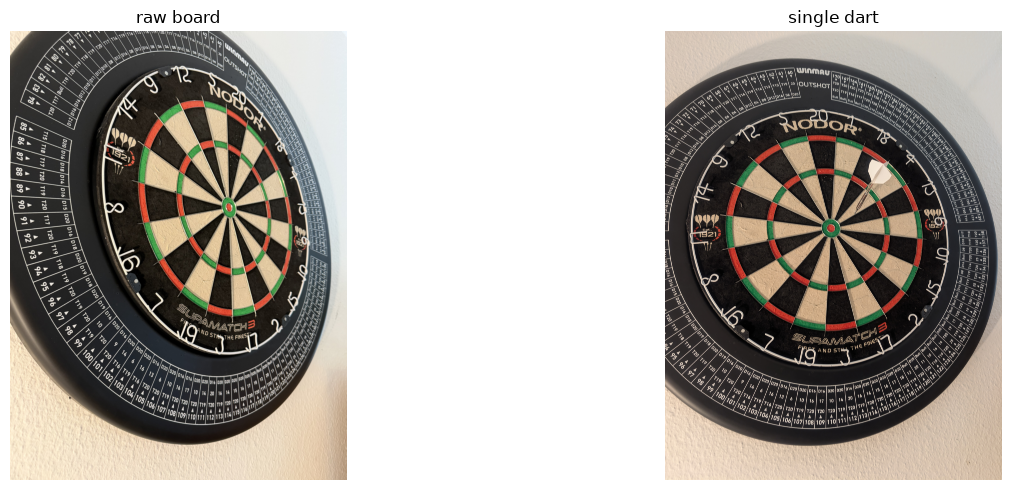

(<Figure size 1600x500 with 2 Axes>,
 array([[<Axes: title={'center': 'raw board'}>,
         <Axes: title={'center': 'single dart'}>]], dtype=object))

In [23]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

from dartcv.detect import detect_board
from dartcv.geometry import RADII
from dartcv.overlay import model_to_topdown, warp_topdown

repo_root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "pyproject.toml").exists()), None)
if repo_root is None:
    raise FileNotFoundError("Could not locate the dartcv repo root")

RAW_BOARD_PATH = repo_root / "data" / "images" / "raw_board" / "IMG_2092.jpg"
RAW_BOARD_PATH = repo_root / "data" / "images" / "raw_board" / "IMG_2091.jpg"
SINGLE_DART_PATH = repo_root / "data" / "images" / "single_dart" / "PXL_20261018_152634348.jpg"

def show_grid(images, titles, cmaps=None, max_cols=2, panel_size=(8, 6)):
    if cmaps is None:
        cmaps = [None] * len(images)
    ncols = min(max_cols, len(images))
    nrows = (len(images) + ncols - 1) // ncols
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(panel_size[0] * ncols, panel_size[1] * nrows),
        squeeze=False,
    )
    for axis, image, title, cmap in zip(axes.flat, images, titles, cmaps):
        axis.imshow(image, cmap=cmap)
        axis.set_title(title)
        axis.axis("off")
    for axis in axes.flat[len(images):]:
        axis.set_visible(False)
    fig.tight_layout()
    plt.show()
    return fig, axes

def bgr_to_rgb(image):
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print(f"Raw board image: {RAW_BOARD_PATH.relative_to(repo_root)}")
print(f"Single-dart image: {SINGLE_DART_PATH.relative_to(repo_root)}")
raw_board = cv2.imread(str(RAW_BOARD_PATH), cv2.IMREAD_COLOR)
single_dart = cv2.imread(str(SINGLE_DART_PATH), cv2.IMREAD_COLOR)
if raw_board is None or single_dart is None:
    raise FileNotFoundError("One or more input images could not be loaded")
show_grid([bgr_to_rgb(raw_board), bgr_to_rgb(single_dart)], ["raw board", "single dart"], max_cols=2, panel_size=(8, 5))


raw H match: (3, 3)
single H match: (3, 3)
raw rotation_deg: 15.0
single rotation_deg: 356.5


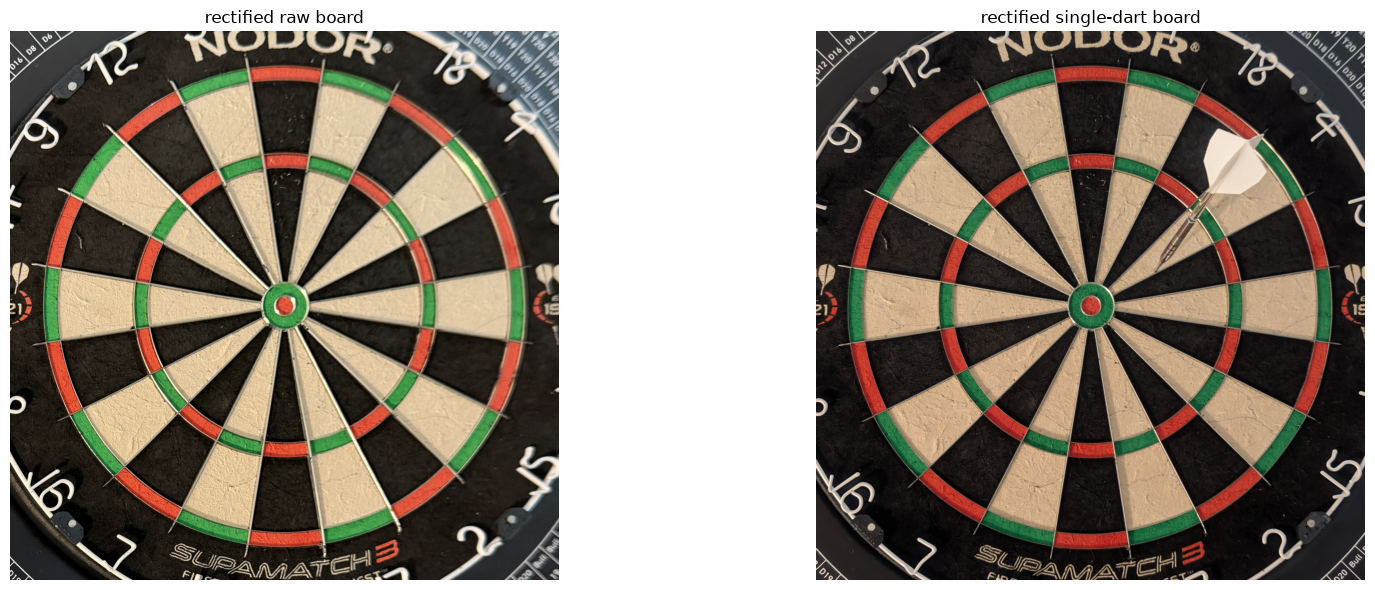

(<Figure size 1800x600 with 2 Axes>,
 array([[<Axes: title={'center': 'rectified raw board'}>,
         <Axes: title={'center': 'rectified single-dart board'}>]],
       dtype=object))

In [24]:
raw_det = detect_board(raw_board, upright_deg=0.0)
single_det = detect_board(single_dart, upright_deg=0.0)

raw_topdown = warp_topdown(raw_board, raw_det.H)
single_topdown = warp_topdown(single_dart, single_det.H)

print(f"raw H match: {raw_det.H.shape}")
print(f"single H match: {single_det.H.shape}")
print(f"raw rotation_deg: {raw_det.rotation_deg:.1f}")
print(f"single rotation_deg: {single_det.rotation_deg:.1f}")
show_grid(
    [bgr_to_rgb(raw_topdown), bgr_to_rgb(single_topdown)],
    ["rectified raw board", "rectified single-dart board"],
    max_cols=2,
    panel_size=(9, 6),
)


## Subtract the board plane

The homography makes both images fronto-parallel. If the board content is the same, the remaining differences should mostly reflect the dart, with some residual noise from lighting, registration, and print variation.

We compare the grayscale top-down views and keep only the board area inside the nominal double-ring radius.

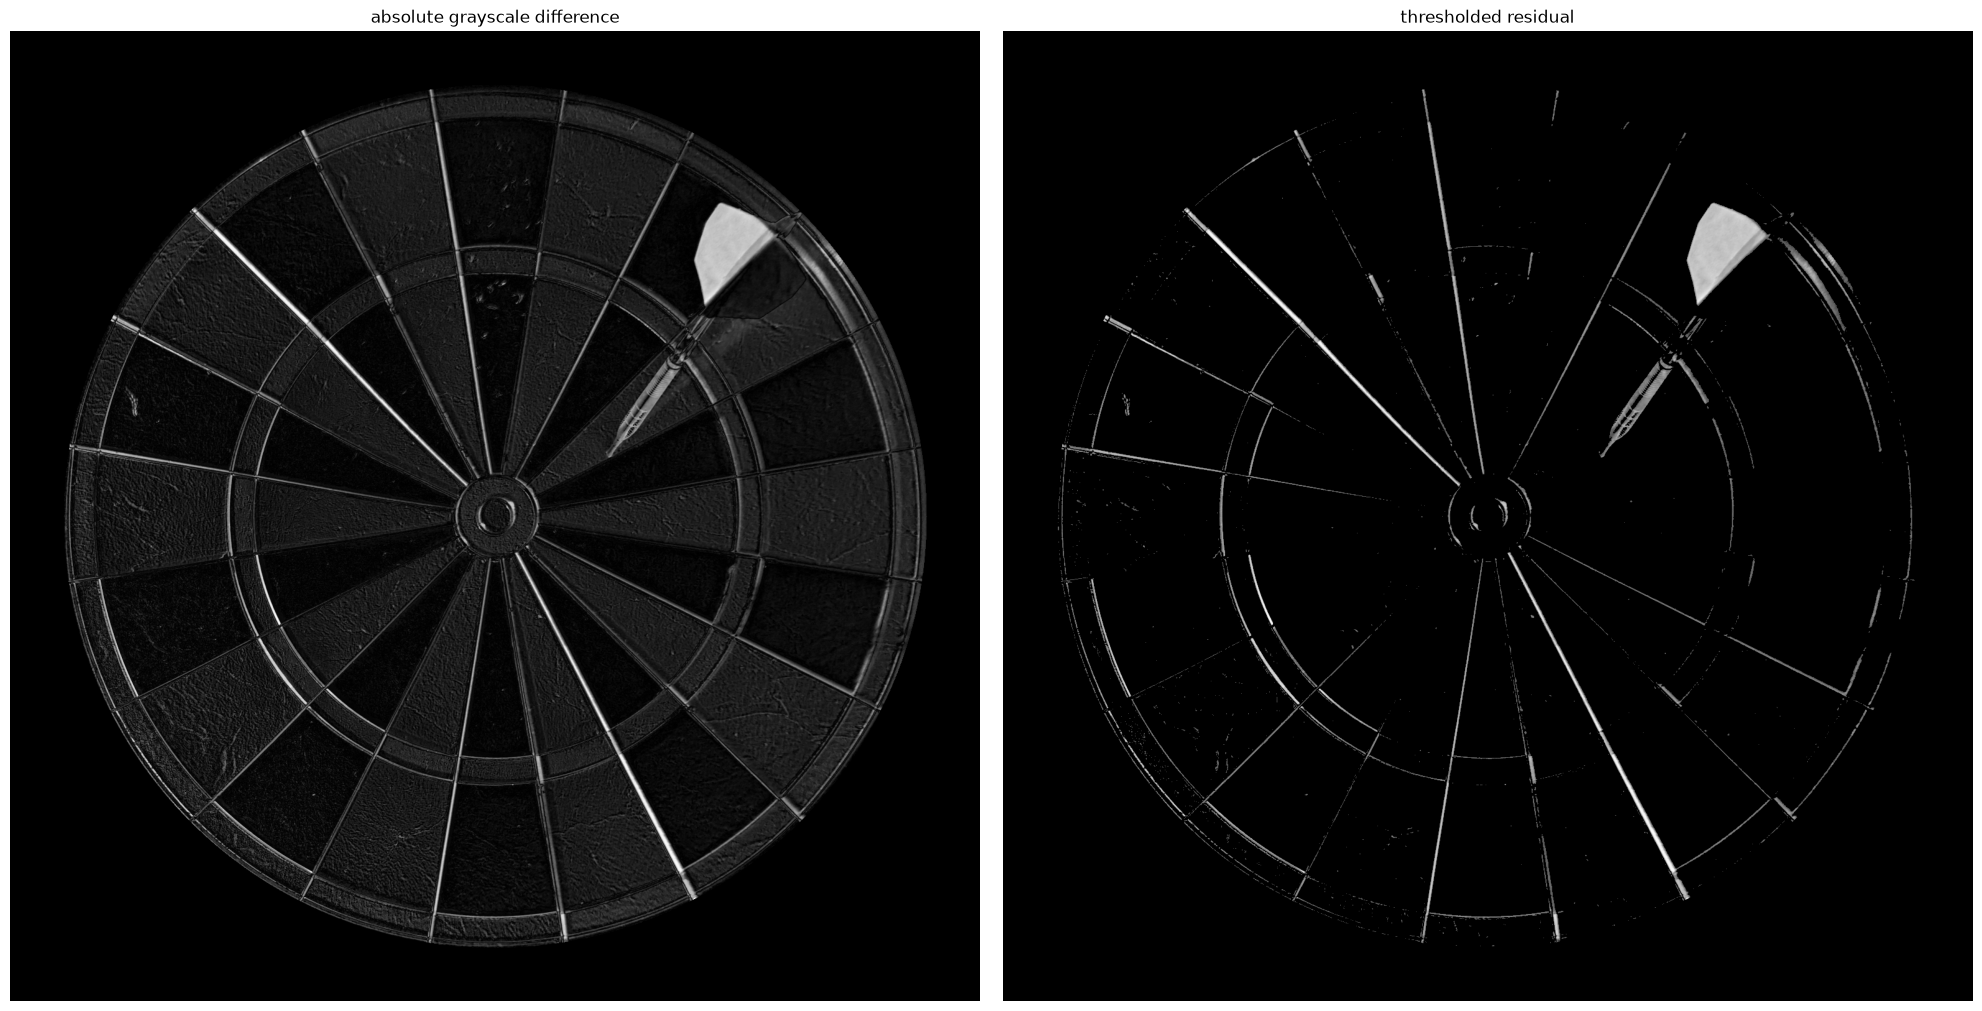

(<Figure size 2000x1000 with 2 Axes>,
 array([[<Axes: title={'center': 'absolute grayscale difference'}>,
         <Axes: title={'center': 'thresholded residual'}>]], dtype=object))

In [25]:
pixels_per_mm = model_to_topdown()[0, 0]
board_radius_px = RADII["double_outer"] * pixels_per_mm * 1.02
height, width = raw_topdown.shape[:2]
center = (width // 2, height // 2)

board_mask = np.zeros((height, width), np.uint8)
cv2.circle(board_mask, center, int(round(board_radius_px)), 255, -1)

gray_raw = cv2.cvtColor(raw_topdown, cv2.COLOR_BGR2GRAY)
gray_single = cv2.cvtColor(single_topdown, cv2.COLOR_BGR2GRAY)
gray_diff = cv2.absdiff(gray_raw, gray_single)
gray_diff[board_mask == 0] = 0

_, gray_diff_thresh = cv2.threshold(gray_diff, 25, 255, cv2.THRESH_BINARY)
# if the threshold is below 50, make the corresponding difference black using the diff_black_out array
diff_black_out = gray_diff.copy()
diff_black_out[diff_black_out < 75] = 0
show_grid(
    [
        gray_diff,
        diff_black_out,
        #cv2.cvtColor(gray_diff_thresh, cv2.COLOR_GRAY2BGR),
    ],
    [
        "absolute grayscale difference",
        "thresholded residual",
    ],
    cmaps=["gray", "gray"],
    panel_size=(10, 10),
)


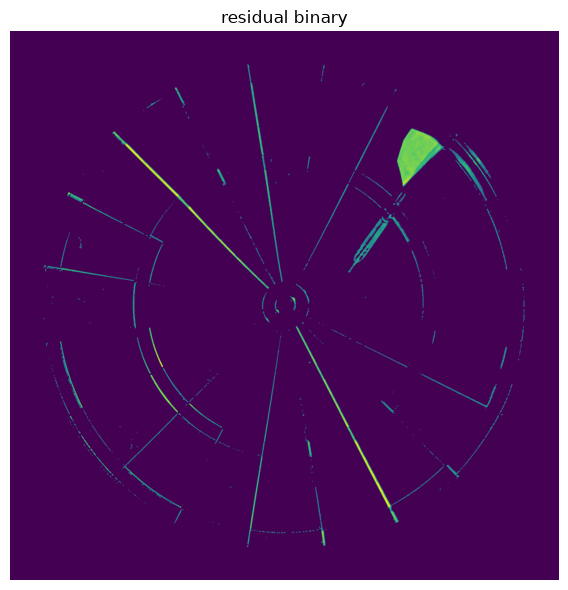

(<Figure size 800x600 with 1 Axes>,
 array([[<Axes: title={'center': 'residual binary'}>]], dtype=object))

In [26]:
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
residual_binary = cv2.morphologyEx(diff_black_out, cv2.MORPH_OPEN, kernel)
residual_binary = cv2.morphologyEx(residual_binary, cv2.MORPH_CLOSE, kernel)
show_grid([residual_binary], ["residual binary"])

In [27]:
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    residual_binary, connectivity=8
)
num_labels, labels, stats, centroids


(389,
 array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], shape=(1560, 1560), dtype=int32),
 array([[      0,       0,    1560,    1560, 2375232],
        [    674,      94,     101,     619,    3313],
        [    889,      96,       6,      13,      45],
        ...,
        [    778,    1424,       6,       3,      14],
        [    727,    1437,       3,       3,       5],
        [    673,    1460,       5,       7,      19]],
       shape=(389, 5), dtype=int32),
 array([[ 777.44432923,  781.67509321],
        [ 723.16812557,  388.76818593],
        [ 891.64444444,  101.66666667],
        [ 888.3877551 ,  118.51020408],
        [ 885.44      ,  137.08      ],
        [1003.42857143,  149.85714286],
        [ 482.5862069 ,  183.77742947],
        [1095.65517241,  167.55172414],
        [1090.        ,  178.        ],
       

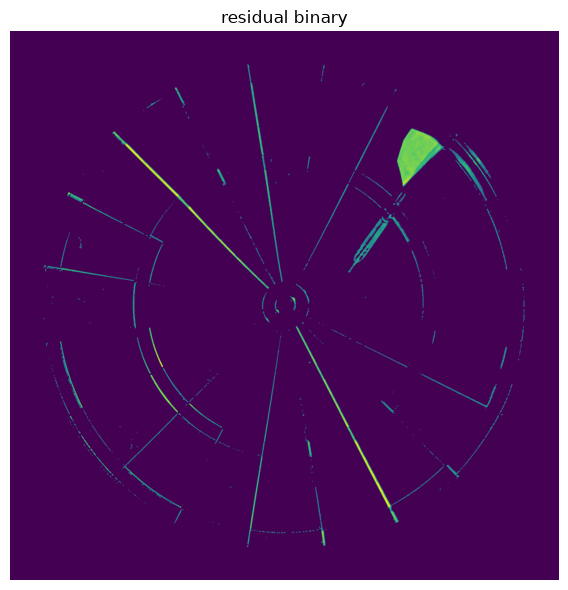

(<Figure size 800x600 with 1 Axes>,
 array([[<Axes: title={'center': 'residual binary'}>]], dtype=object))

In [28]:
show_grid([residual_binary], ["residual binary"])

Label 1: x=675, y=96, w=6, h=10, area=41, occupancy=0.6833333333333333
Label 2: x=683, y=145, w=73, h=446, area=2563, occupancy=0.07872105166164999
Label 3: x=469, y=159, w=26, h=46, area=287, occupancy=0.2399665551839465
Label 4: x=401, y=204, w=6, h=6, area=24, occupancy=0.6666666666666666
Label 5: x=1048, y=257, w=5, h=5, area=17, occupancy=0.68
Label 6: x=1100, y=276, w=133, h=165, area=11504, occupancy=0.5242196400091137
Label 7: x=293, y=284, w=443, h=448, area=4527, occupancy=0.02281018219929055
Label 8: x=1303, y=331, w=57, h=74, area=732, occupancy=0.17354196301564723
Label 9: x=1256, y=338, w=94, h=133, area=1660, occupancy=0.13277875539913614
Label 10: x=1316, y=366, w=11, h=13, area=61, occupancy=0.42657342657342656
Label 11: x=988, y=375, w=5, h=5, area=17, occupancy=0.68
Label 12: x=589, y=392, w=24, h=43, area=308, occupancy=0.29844961240310075
Label 13: x=955, y=440, w=5, h=5, area=17, occupancy=0.68
Label 14: x=950, y=450, w=5, h=5, area=17, occupancy=0.68
Label 15: x=

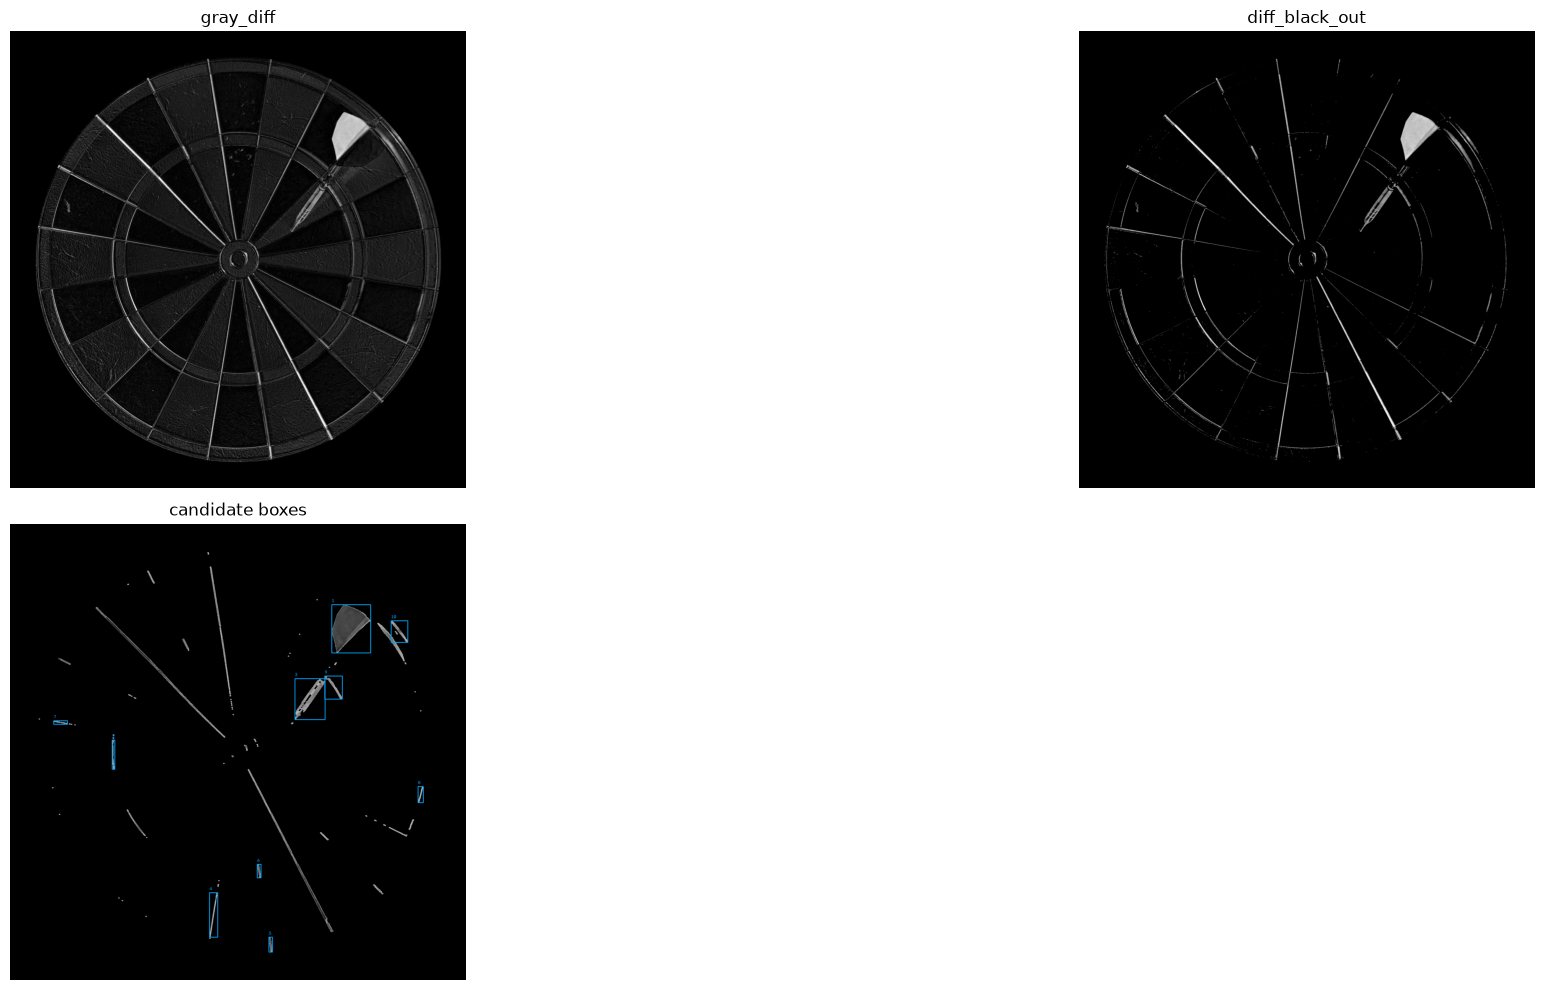

(<Figure size 2400x1000 with 4 Axes>,
 array([[<Axes: title={'center': 'gray_diff'}>,
         <Axes: title={'center': 'diff_black_out'}>],
        [<Axes: title={'center': 'candidate boxes'}>, <Axes: >]],
       dtype=object))

In [29]:
def score_candidate(stats, center, image_shape):
    x, y, w, h, area = stats
    height, width = image_shape[:2]
    cx = x + w / 2.0
    cy = y + h / 2.0
    aspect = max(w, h) / max(1, min(w, h))
    dist = np.hypot(cx - center[0], cy - center[1])
    max_radius = 0.9 * min(width, height) / 2.0
    # Keep a simple, explainable heuristic: moderate-to-large residuals that
    # are elongated and are not in the exact centre of the board.
    score = area / 250.0 + aspect * 1.5
    score -= dist / max_radius * 1.5
    return score

residual_binary = (diff_black_out > 0).astype(np.uint8)
residual_binary = diff_black_out

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
residual_binary = cv2.morphologyEx(residual_binary, cv2.MORPH_OPEN, kernel)
residual_binary = cv2.morphologyEx(residual_binary, cv2.MORPH_CLOSE, kernel)

num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    residual_binary, connectivity=8
)

candidates = []
for label in range(1, num_labels):
    x, y, w, h, area = stats[label]
    occupancy = area / (w * h)
    print(f"Label {label}: x={x}, y={y}, w={w}, h={h}, area={area}, occupancy={occupancy}")
    if area < 50 or w < 4 or h < 4 or occupancy < 0.15:
        continue
    aspect = max(w, h) / max(1, min(w, h))
    cx, cy = centroids[label]
    dist = np.hypot(cx - center[0], cy - center[1])
    score = score_candidate(stats[label], center, gray_diff.shape)
    if area > 150 and aspect > 1.1 and dist < 0.9 * min(height, width) / 2:
        candidates.append({
            "label": label,
            "area": int(area),
            "x": int(x),
            "y": int(y),
            "w": int(w),
            "h": int(h),
            "aspect": float(aspect),
            "distance": float(dist),
            "score": float(score),
        })

candidates.sort(key=lambda item: item["score"], reverse=True)
print(f"Residual components after cleanup: {len(candidates)} plausible candidates")
for index, cand in enumerate(candidates[:10], start=1):
    print(
        index,
        round(cand["score"], 2),
        cand["area"],
        cand["x"],
        cand["y"],
        cand["w"],
        cand["h"],
        round(cand["aspect"], 2),
        round(cand["distance"], 1),
    )

candidate_view = cv2.cvtColor(residual_binary * 255, cv2.COLOR_GRAY2BGR)
for index, cand in enumerate(candidates[:10], start=1):
    x, y, w, h = cand["x"], cand["y"], cand["w"], cand["h"]
    cv2.rectangle(candidate_view, (x, y), (x + w, y + h), (0, 165, 255), 2)
    cv2.putText(
        candidate_view,
        str(index),
        (x, max(y - 8, 12)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (0, 165, 255),
        1,
        cv2.LINE_AA,
    )

show_grid(
    [gray_diff, diff_black_out, candidate_view],
    ["gray_diff", "diff_black_out", "candidate boxes"],
    cmaps=["gray", "gray", None],
    panel_size=(12, 5),
)

In [30]:
79*65

5135

In [31]:
gray_diff

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(1560, 1560), dtype=uint8)

## Prototype: residual-based dart candidate detector

This prototype turns the difference map into a small candidate detector. It does not claim to be a final dart finder; it is a practical way to turn the residual into a few believable blob candidates for inspection.

The logic is:
- keep only the board area
- remove tiny noise
- find connected residual components
- score each component by how dart-like its size, shape, and distance from the board center look


Residual components after cleanup: 19 plausible candidates
1 46.65 11504 1100 276 133 165 1.24 572.4
2 20.36 4579 813 838 293 559 1.91 407.3
3 18.53 2563 683 145 73 446 6.11 427.3
4 17.53 443 349 739 9 100 11.11 428.2
5 14.98 3397 974 529 103 140 1.36 308.1
6 9.72 696 682 1261 28 152 5.43 565.2
7 7.39 1660 1256 338 94 133 1.41 648.9
8 6.32 344 885 1413 12 51 4.25 667.3
9 5.61 297 845 1164 13 46 3.54 412.6
10 5.32 189 149 673 47 12 3.92 617.5


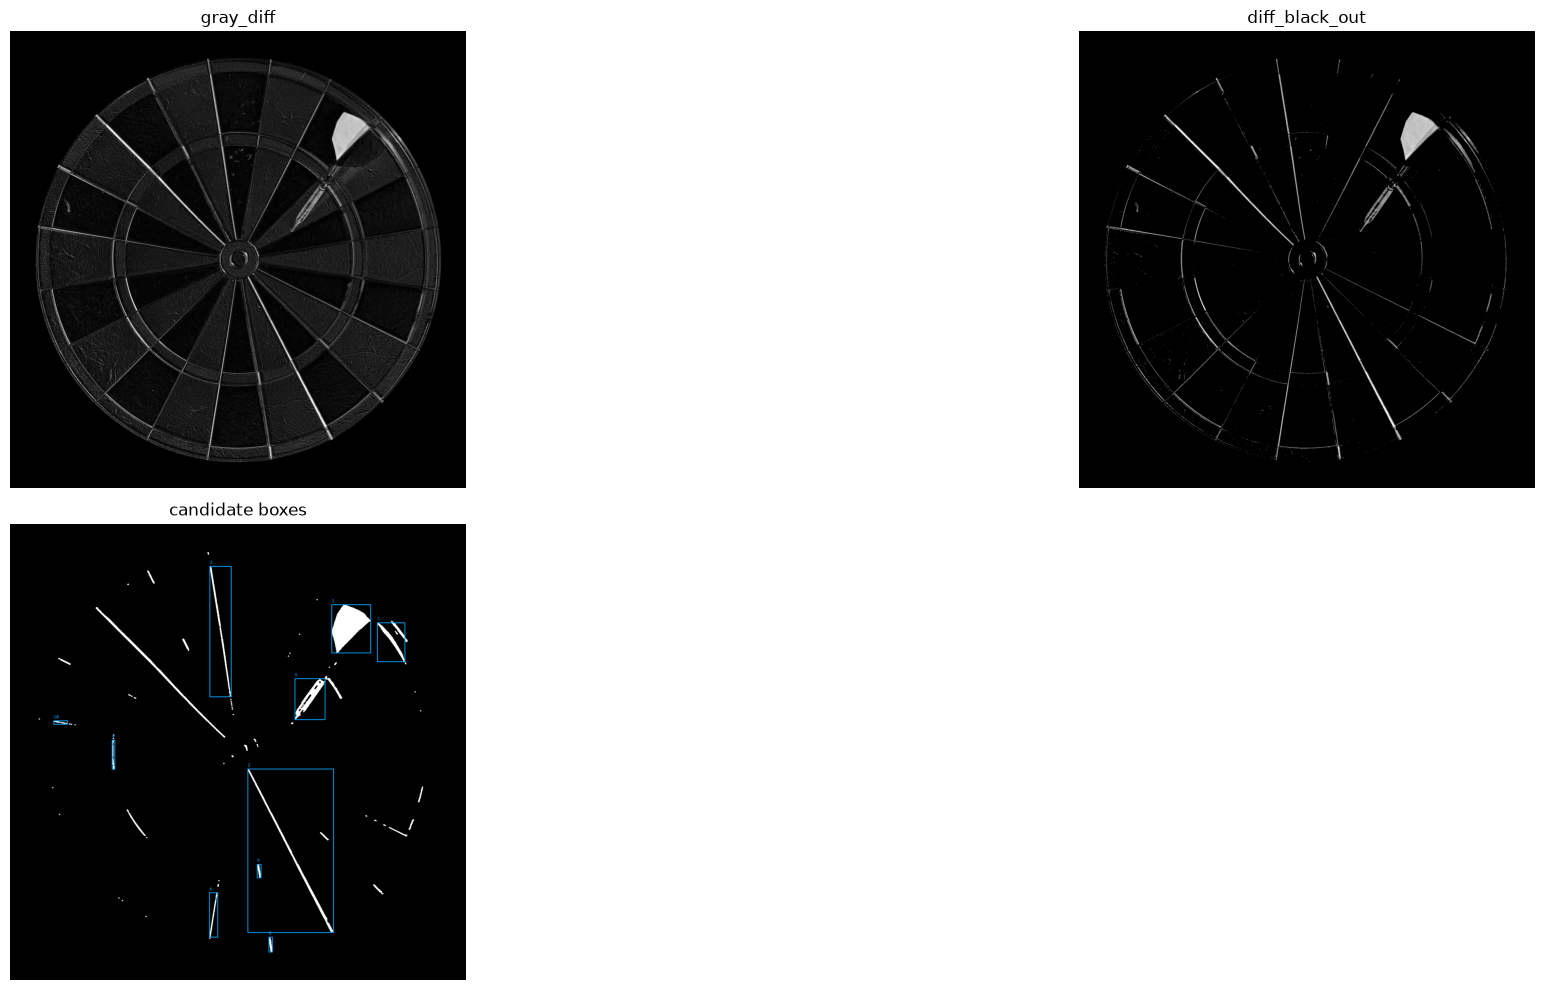

(<Figure size 2400x1000 with 4 Axes>,
 array([[<Axes: title={'center': 'gray_diff'}>,
         <Axes: title={'center': 'diff_black_out'}>],
        [<Axes: title={'center': 'candidate boxes'}>, <Axes: >]],
       dtype=object))

In [32]:
def score_candidate(stats, center, image_shape):
    x, y, w, h, area = stats
    height, width = image_shape[:2]
    cx = x + w / 2.0
    cy = y + h / 2.0
    aspect = max(w, h) / max(1, min(w, h))
    dist = np.hypot(cx - center[0], cy - center[1])
    max_radius = 0.9 * min(width, height) / 2.0
    # Keep a simple, explainable heuristic: moderate-to-large residuals that
    # are elongated and are not in the exact centre of the board.
    score = area / 250.0 + aspect * 1.5
    score -= dist / max_radius * 1.5
    return score

residual_binary = (diff_black_out > 0).astype(np.uint8)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
residual_binary = cv2.morphologyEx(residual_binary, cv2.MORPH_OPEN, kernel)
residual_binary = cv2.morphologyEx(residual_binary, cv2.MORPH_CLOSE, kernel)

num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    residual_binary, connectivity=8
)

candidates = []
for label in range(1, num_labels):
    x, y, w, h, area = stats[label]
    if area < 50 or w < 4 or h < 4:
        continue
    aspect = max(w, h) / max(1, min(w, h))
    cx, cy = centroids[label]
    dist = np.hypot(cx - center[0], cy - center[1])
    score = score_candidate(stats[label], center, gray_diff.shape)
    if area > 150 and aspect > 1.1 and dist < 0.9 * min(height, width) / 2:
        candidates.append({
            "label": label,
            "area": int(area),
            "x": int(x),
            "y": int(y),
            "w": int(w),
            "h": int(h),
            "aspect": float(aspect),
            "distance": float(dist),
            "score": float(score),
        })

candidates.sort(key=lambda item: item["score"], reverse=True)
print(f"Residual components after cleanup: {len(candidates)} plausible candidates")
for index, cand in enumerate(candidates[:10], start=1):
    print(
        index,
        round(cand["score"], 2),
        cand["area"],
        cand["x"],
        cand["y"],
        cand["w"],
        cand["h"],
        round(cand["aspect"], 2),
        round(cand["distance"], 1),
    )

candidate_view = cv2.cvtColor(residual_binary * 255, cv2.COLOR_GRAY2BGR)
for index, cand in enumerate(candidates[:10], start=1):
    x, y, w, h = cand["x"], cand["y"], cand["w"], cand["h"]
    cv2.rectangle(candidate_view, (x, y), (x + w, y + h), (0, 165, 255), 2)
    cv2.putText(
        candidate_view,
        str(index),
        (x, max(y - 8, 12)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (0, 165, 255),
        1,
        cv2.LINE_AA,
    )

show_grid(
    [gray_diff, diff_black_out, candidate_view],
    ["gray_diff", "diff_black_out", "candidate boxes"],
    cmaps=["gray", "gray", None],
    panel_size=(12, 5),
)


## Interpretation

The board subtraction is a useful quick-probe for a single dart on a different board image, but it is not a fully reliable detector on its own. The residual often includes a dart-shaped patch, yet it can also be contaminated by:

- small misalignment of the board homography
- lighting and exposure changes
- board printing or wear differences
- a ghosted or rotated dart from imperfect registration

So the subtraction is a good signal to inspect, but it needs additional constraints (connected-component filtering, circular search masks, motion or edge models, or a template of the dart shape) before it could be used as a robust detection pipeline.

## Compact batch: final outputs only

Set `RUN_BATCH = True` and edit `BATCH_PATHS` to select any subset (remove `[:3]`
for the full directory). Run this cell again without repeating the intermediate
visualizations. Processing is sequential; pages retain small output thumbnails,
not full-resolution diagnostic histories. Each tile names the input, final
status and processing time. Failures are visible, not silently skipped.

To investigate a bad tile, copy its filename into this notebook's single-image
selection and rerun the detailed sections. Batch mode uses automatic calibration;
never reuse one image's manual points/tips on another image.

Runs the final binary residual/candidate recipe against one explicit raw-board reference. The reference is cached only within this cell run; no coordinates transfer between images.

In [ ]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from dartcv.notebook_batch import BatchOutput, image_batch_figures, read_batch_image

BATCH_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())

RUN_BATCH = False
BATCH_PATHS = sorted((BATCH_ROOT / "data/images/single_dart").glob("*.jpg"))[:3]

from dartcv.detect import detect_board
from dartcv.geometry import RADII
from dartcv.overlay import model_to_topdown, warp_topdown

BATCH_REFERENCE_PATH = BATCH_ROOT / "data/images/raw_board/IMG_2091.jpg"
_batch_reference_cache = None

def batch_output(path):
    global _batch_reference_cache
    if _batch_reference_cache is None:
        reference = read_batch_image(BATCH_REFERENCE_PATH)
        _batch_reference_cache = warp_topdown(reference, detect_board(reference).H)
    source = read_batch_image(path)
    topdown = warp_topdown(source, detect_board(source).H)
    gray = cv2.absdiff(cv2.cvtColor(topdown, cv2.COLOR_BGR2GRAY),
                      cv2.cvtColor(_batch_reference_cache, cv2.COLOR_BGR2GRAY))
    height, width = gray.shape
    yy, xx = np.ogrid[:height, :width]
    center = (width//2, height//2)
    radius = RADII["double_outer"] * model_to_topdown()[0, 0] * 1.02
    support = ((gray >= 75) & ((xx-center[0])**2 + (yy-center[1])**2 <= radius**2)).astype(np.uint8)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    support = cv2.morphologyEx(cv2.morphologyEx(support, cv2.MORPH_OPEN, kernel), cv2.MORPH_CLOSE, kernel)
    count, labels, stats, centroids = cv2.connectedComponentsWithStats(support, connectivity=8)
    candidates = []
    for label in range(1, count):
        x, y, w, h, area = stats[label]
        if area < 50 or w < 4 or h < 4:
            continue
        aspect = max(w, h) / max(1, min(w, h))
        cx, cy = centroids[label]
        distance = np.hypot(cx-center[0], cy-center[1])
        if area > 150 and aspect > 1.1 and distance < .9*min(height, width)/2:
            score = area/250 + aspect*1.5 - distance/(.9*min(width, height)/2)*1.5
            candidates.append((score, int(x), int(y), int(w), int(h)))
    output = cv2.cvtColor(support*255, cv2.COLOR_GRAY2BGR)
    for score, x, y, w, h in sorted(candidates, reverse=True)[:10]:
        cv2.rectangle(output, (x, y), (x+w, y+h), (0, 165, 255), 2)
    return BatchOutput(output, f"Reference-difference candidates: {min(10, len(candidates))}; alignment may dominate")

if RUN_BATCH:
    for batch_figure in image_batch_figures(BATCH_PATHS, batch_output, page_size=6):
        display(batch_figure)
        plt.close(batch_figure)